# 04b — Four views of AI

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/04b_four_views_of_AI.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

An AI system can be assessed for resemblance to human behavior, resemblance to human thought, logical validity or success at an objective. These are different questions. A system may perform well under one criterion and poorly under another without contradiction. This notebook turns the familiar four-view classification of AI into a tool for formulating evaluations.

The code prints a catalogue, renders a grid and retrieves entries by keyword. Use it to turn each view into an evaluation question, with a task, observable result and criterion for success.

### Learning goals

1. Distinguish thinking from acting, and human resemblance from normative success.
2. Turn each quadrant into a concrete evaluation question.
3. Explain why behavioral imitation, logical validity and utility cannot be substituted for one another.
4. Locate a claim in the paper or talk within the criteria it actually addresses.


## Concepts and two reading paths

<details open>
<summary><strong>For biomedical and imaging readers</strong></summary>

**Thinking humanly** asks whether a proposed internal process resembles measured human cognition. Response patterns alone may leave several processes possible; timing, error patterns and interventions can add constraints.

**Acting humanly** asks whether observed behavior resembles human performance. A conversational imitation test addresses an interface under stated conditions. It does not directly measure a mechanism, subjective experience or clinical usefulness.

**Thinking rationally** concerns valid inference under explicit premises and rules. A valid argument can still start from a false premise. **Acting rationally** concerns choosing actions that serve a stated objective given information and constraints. The objective must be specified and justified.

For a diagnostic tool, agreement with a clinician, formal consistency, predictive accuracy and patient benefit are four distinct kinds of evidence. Ask which one a reported result actually measures.

</details>

<details>
<summary><strong>For computational readers</strong></summary>

Think of each view as a different evaluation functional on a system and its environment. Human resemblance requires a reference distribution or process model. Logical validity requires a formal language and inference relation. Rational action requires an objective, uncertainty model and admissible actions.

Maximizing expected utility, $a^*=\arg\max_a\mathbb E[U\mid a]$, is meaningful only after $U$, the predictive distribution and constraints are fixed. Accuracy is one possible objective, not a universal substitute for utility. Behavioral agreement is another statistic, not an estimator of logical validity.

The two axes are an organizing taxonomy. A real study can occupy several cells and use several metrics. The grid neither partitions all research neatly nor proves that a model satisfies an entire quadrant because it passed one benchmark.

</details>


### Run in Colab or locally

**Colab:** click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells (**Runtime → Run all**). Setup obtains the shared code and numerical dependencies.

**Locally:** follow the [environment instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select the project's Python kernel in Cursor or JupyterLab. Setup locates the checkout and sets the working directory to `code/notebooks`, so `%load ../solutions/<filename>.py` works in either environment.

Use **File → Save a copy in Drive** to retain Colab notebook edits, and download generated files before the runtime ends. See the [execution guide](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/README.md#running-and-saving) for saving outputs and starting a fresh runtime.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.four_views import (
    QUADRANTS,
    format_quadrant,
    lookup,
    render_paper_figure,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)
print(len(QUADRANTS), "quadrants in the catalogue")

Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2
repo root: CHECKOUT
seed: 7
4 quadrants in the catalogue


## The two axes

Thinking humanly asks about cognitive processes; acting humanly asks about observable imitation. Thinking rationally asks about validity; acting rationally asks about decisions under a stated objective and information. These are evaluation perspectives, not verdicts on current systems.


In [2]:
for cell in QUADRANTS:
    print(f"{cell.title:<22}  {cell.aima:<20}  {cell.verdict}")

Thinking humanly        Cognitive science     compare behavior and proposed mechanisms
Thinking rationally     Laws of thought       test validity and consistency
Acting humanly          Turing test           specify the imitation test
Acting rationally       Rational agent        state the objective and information available


## Four evaluation criteria

The diagram places each criterion on the two axes. It supplies questions for an evaluation, without assigning capability scores.

**Before running.** For each cell, write an example of a successful result and a result that would fail that criterion. Use the same proposed system across all four cells. You should end up with different evaluation procedures, rather than four ways of restating one overall accuracy score.


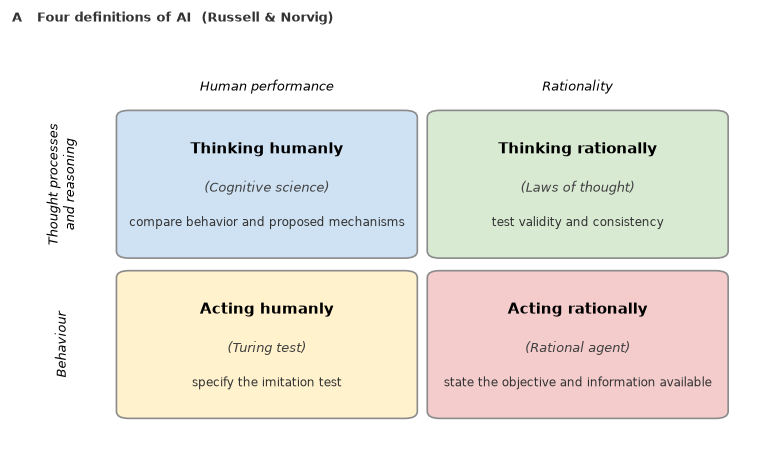

wrote CHECKOUT/paper/figures/four_views.pdf


wrote CHECKOUT/paper/figures/four_views.png


PosixPath('CHECKOUT/paper/figures/four_views.pdf')

In [3]:
fig = render_paper_figure()
plt.show()
write_figure(root / "paper" / "figures")

## Look up a cell

Try `turing`, `corpus`, `validity`, `goals`, `04` or `02b`. The search matches substrings in the catalog.


In [4]:
FOCUS = "turing"
hits = lookup(FOCUS)
if not hits:
    print("Nothing matched. Try turing, corpus, proof, goals, framing, agent.")
for cell in hits:
    print(format_quadrant(cell))
    print()

Acting humanly  (Turing test)
  axes     behaviour × human
  criterion specify the imitation test
  see      code/notebooks/01_tiny_transformer.ipynb
  Score the public interface of thought: the strings a person might produce. Results depend on the task, interaction and judges. Successful imitation does not by itself identify the underlying mechanism or establish subjective experience.



## Use the grid to design an evaluation

Choose one system, such as an imaging assistant that proposes a region and a report. Under acting humanly, you might measure whether experts can distinguish its reports from human reports. Under thinking humanly, you would need a hypothesis about the process producing them and observations that discriminate it from alternatives. Under thinking rationally, you could test whether stated conclusions follow from explicit premises. Under acting rationally, you would specify downstream actions and assess their consequences under an appropriate study design.

None of these measurements automatically supplies the others. A convincing report can contain an invalid inference. A valid inference from incorrect input can recommend a harmful action. An output that differs from the average human answer can still be useful under a well-justified objective. The point is to make the target and evidence visible before judging performance.

### Read the figure as questions

The cells name evaluation criteria, rather than declare what every language model can or cannot do. Search for `turing`, `proof`, `goals` or `framing` and explain why each term belongs to a criterion. Then write a counterexample to the inference that success in one cell guarantees success in an adjacent cell.

Connect this exercise to notebook 04: a learned framing completion is a behavioral output, with a particular probability measurement. It does not by itself establish human-like internal reasoning. Connect it to notebook 13: numerical verification checks an implementation against equations; clinical benefit would require a different evaluation. This taxonomy helps keep those claims aligned with their evidence.

**Discussion task.** Select a sentence containing "human-like," "rational" or "intelligent." Replace the broad label with a measurable criterion, a dataset or environment, and a failure condition. The revised sentence should be easier to test even if it sounds less sweeping.


### Exercises

1. **One system, four evaluation questions.** Inspect the four catalog entries using `lookup`. Matches depend on the actual text and need not be unique. For one clinical note-completer, propose an evaluation under each criterion and identify the required evidence.

<!-- solution-box: 04b_1_one_system_four_scores.py -->
<details>
<summary><strong>Show solution</strong> — One system, four evaluation questions</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/04b_1_one_system_four_scores.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.four_views import format_quadrant, lookup
for query in ("mechanisms", "validity", "imitation", "goals"):
    hits = lookup(query)
    print(f"query {query!r}  →  {len(hits)} cell(s)")
    for cell in hits:
        print(" ", cell.title, "—", cell.verdict)
    print()
print('The catalog lists four evaluation criteria. For a clinical note-completer, specify a behavioral or mechanistic comparison, a validity check, an imitation test and an explicit decision objective. No scores are measured here.')
```

</details>
<!-- /solution-box -->


2. **Design the missing exercise.** Identify the criterion with no companion notebook. Propose an exercise that checks argument validity against an independent reference. How would you distinguish a plausible explanation from a verified result?

<!-- solution-box: 04b_2_the_empty_companion.py -->
<details>
<summary><strong>Show solution</strong> — Design the missing exercise</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/04b_2_the_empty_companion.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.four_views import QUADRANTS, format_quadrant
for cell in QUADRANTS:
    flag = cell.companion or "(none)"
    print(f"{cell.title:<22}  companion {flag}")
print()
empty = [c for c in QUADRANTS if not c.companion]
print(format_quadrant(empty[0]))
print('The missing companion marks a gap in this collection. A useful addition could compare generated arguments with a proof checker or independently verified answers. The training objective alone does not determine whether reasoning succeeds.')
```

</details>
<!-- /solution-box -->


3. **Inspect catalog matching.** Try `human` and a string absent from the catalog. Count the actual substring matches and explain why these counts do not measure model capability.

<!-- solution-box: 04b_3_lookup_is_not_a_proof.py -->
<details>
<summary><strong>Show solution</strong> — Inspect catalog matching</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/04b_3_lookup_is_not_a_proof.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.four_views import format_quadrant, lookup
for q in ("human", "not a word in the catalogue", "04", "02b"):
    hits = lookup(q)
    print(f"{q!r:40}  {len(hits)} hit(s):", ", ".join(c.title for c in hits) or "—")
print()
print('Substring matches describe this catalog. They do not evaluate a model. Count the actual matches and identify the text responsible for each one.')
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. What do the two axes of the Russell–Norvig grid distinguish?

2. What should be specified in an imitation test?

3. How could a generated reasoning trace be evaluated?

4. What belongs in an evaluation of rational action?

5. Which claims in the grid are hypotheses rather than results?


### Further reading

1. **Russell, S., and Norvig, P. (2021).** [*Artificial Intelligence: A Modern Approach*](https://aima.cs.berkeley.edu/). 4th ed., Pearson. Book site.
2. **Turing, A. M. (1950).** [*Computing Machinery and Intelligence*](https://redirect.cs.umbc.edu/courses/471/papers/turing.pdf). *Mind* 59(236), 433–460.
3. **Binz, M., and Schulz, E. (2023).** [*Using cognitive psychology to understand GPT-3*](https://www.pnas.org/doi/10.1073/pnas.2218523120). *PNAS* 120(6), e2218523120.
4. **Ouyang, L., et al. (2022).** [*Training language models to follow instructions with human feedback*](https://arxiv.org/abs/2203.02155). *NeurIPS* 35. arXiv:2203.02155.
5. **Bommasani, R., et al. (2021).** [*On the Opportunities and Risks of Foundation Models*](https://arxiv.org/abs/2108.07258). arXiv:2108.07258.
6. **Gabriel, I. (2020).** [*Artificial intelligence, values, and alignment*](https://arxiv.org/pdf/2001.09768). *Minds and Machines* 30, 411–437. arXiv:2001.09768.
